# Spam / Normal E-posta Sınıflandırma

Bu not defteri ödevin adımlarını sırayla gösterir: veri seti incelemesi, ön işleme, 6 makine öğrenmesi algoritmasının eğitimi, test kümesinde karşılaştırma ve en iyi algoritmanın seçimi.

Hiperparametre araması (5-katlı GridSearchCV) uzun sürdüğü için `spam_classification.py` betiğinde yapılır; burada betiğin bulduğu en iyi parametrelerle modeller yeniden eğitilir ve test edilir.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import spam_classification as sc
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Veri seti: Enron-Spam

Enron şirketinin 6 çalışanının gerçek posta kutularından alınan normal (ham) e-postalar ile farklı spam tuzaklarından toplanan spam e-postaların birleşimidir (Metsis vd., 2006).

In [2]:
raw = pd.read_csv(sc.ENRON_PATH)
print(raw.shape)
raw.head()

(33716, 5)


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


In [3]:
raw['Spam/Ham'].value_counts().plot.bar(color=['#e76f51', '#2a9d8f'], title='Sınıf dağılımı (ham veri)')
plt.show()

## 2. Ön işleme

* Konu + gövde birleştirilir, küçük harfe çevrilir.
* URL → `urltoken`, e-posta adresi → `emailtoken`, sayı → `numtoken`.
* Harf dışı karakterler silinir.
* Boş ve **tekrarlı** metinler atılır (aynı e-postanın hem eğitimde hem testte olması sonucu şişirir).

In [4]:
df = sc.load_enron()
df['kelime_sayisi'] = df['text'].str.split().str.len()
df.head()

[Enron-Spam] ham kayıt: 33716 | boş atılan: 52 | tekrarlı atılan: 4664 | kalan: 29000 (ham=14494, spam=14506)


,raw,text,label,kelime_sayisi
0,christmas tree farm pictures,christmas tree farm pictures,0,4
1,"vastar resources , inc . gary , production fro...",vastar resources inc gary production from the ...,0,432
2,calpine daily gas nomination - calpine daily g...,calpine daily gas nomination calpine daily gas...,0,10
3,re : issue fyi - see note below - already done...,re issue fyi see note below already done stell...,0,177
4,meter 7268 nov allocation fyi .\n- - - - - - -...,meter numtoken nov allocation fyi forwarded by...,0,170


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df.assign(sinif=df['label'].map({0: 'ham', 1: 'spam'})), x='kelime_sayisi',
             hue='sinif', bins=80, log_scale=True, element='step', ax=ax)
ax.set_title('E-posta uzunluğu dağılımı (kelime, log ölçek)')
plt.show()
df.groupby('label')['kelime_sayisi'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,14494.0000,278.0123,913.8324,1.0000,64.0000,141.0000,284.0000,37137.0000
1,14506.0000,208.5010,307.1686,1.0000,55.0000,103.0000,217.0000,6000.0000


## 3. Eğitim / test ayrımı

Stratified %80 eğitim, %20 test (`random_state=42`).

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, stratify=df['label'], random_state=sc.RANDOM_STATE)
len(X_train), len(X_test)

(23200, 5800)

## 4. Modellerin eğitimi ve testi

Her model `TF-IDF → sınıflandırıcı` boru hattıdır. Parametreler `results/results.csv` dosyasındaki GridSearch sonuçlarından alınır.

In [7]:
best_params = pd.read_csv(sc.OUT / 'results.csv').set_index('Model')['En iyi parametreler']
rows, fitted = [], {}
for name, (clf, _) in sc.get_models().items():
    pipe = Pipeline([('tfidf', sc.make_tfidf()), ('clf', clf)])
    params = json.loads(best_params[name])
    params = {k: tuple(v) if isinstance(v, list) else v for k, v in params.items()}
    pipe.set_params(**params).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, sc.score_for_auc(pipe, X_test))})
    fitted[name] = pipe
res = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
res

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Linear SVM,0.9928,0.9881,0.9976,0.9928,0.9989
1,Naive Bayes,0.9919,0.9914,0.9924,0.9919,0.9996
2,Logistic Regression,0.9917,0.9870,0.9966,0.9918,0.9987
3,KNN,0.9867,0.9859,0.9876,0.9867,0.9983
4,Random Forest,0.9845,0.9763,0.9931,0.9846,0.9971
5,Decision Tree,0.9547,0.9362,0.9759,0.9556,0.9510


## 5. Karşılaştırma grafikleri

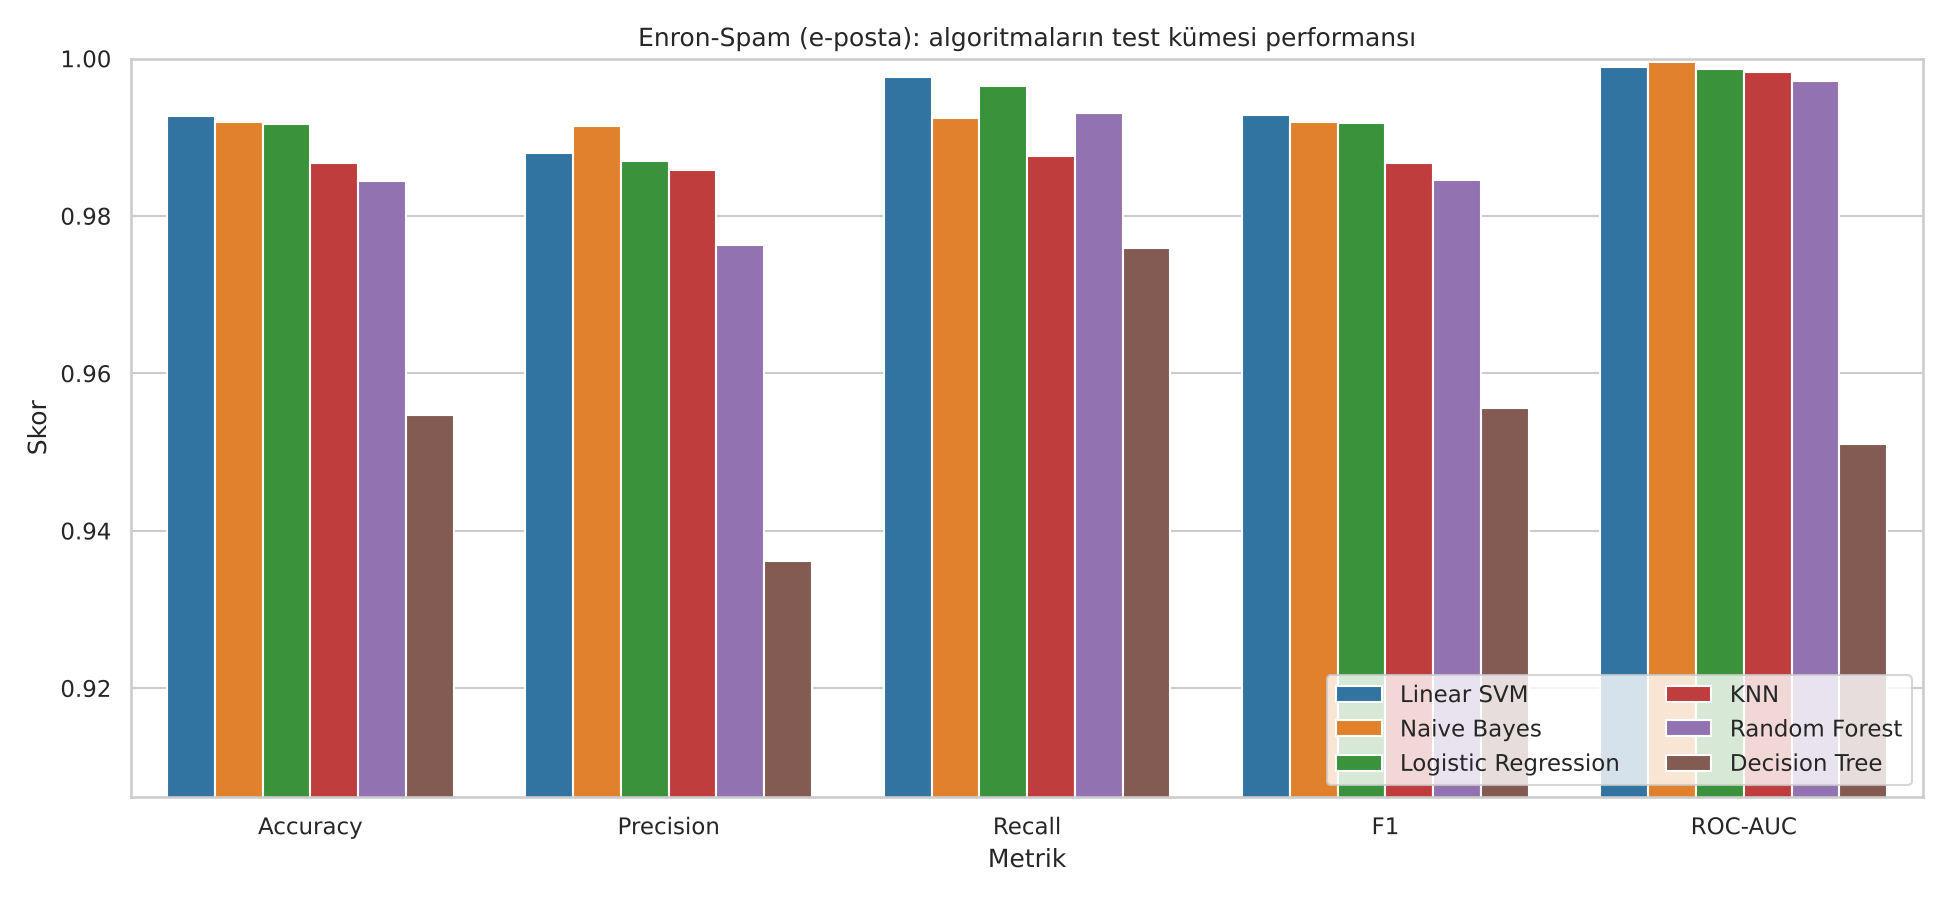

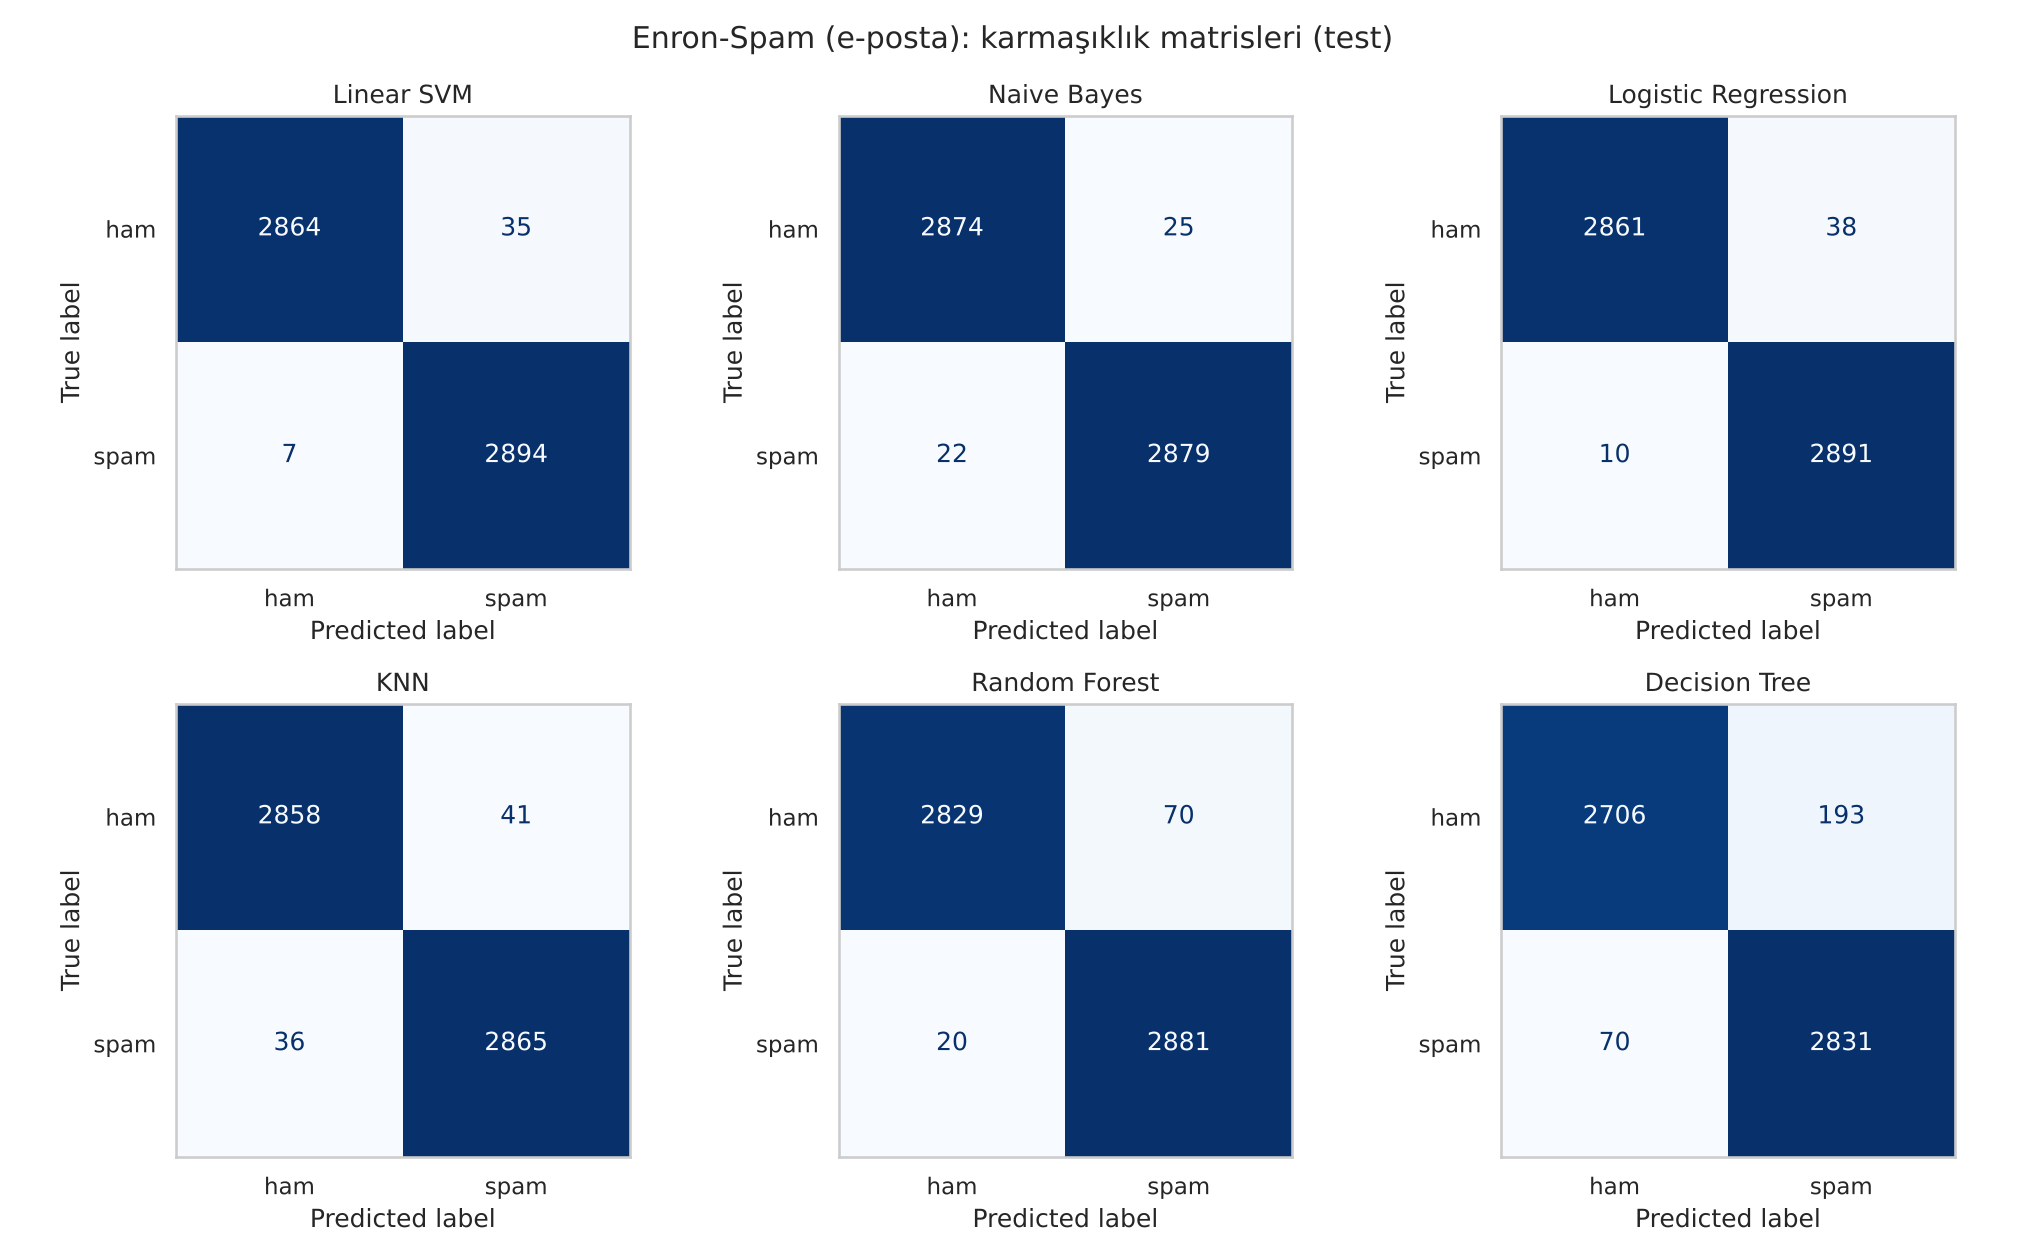

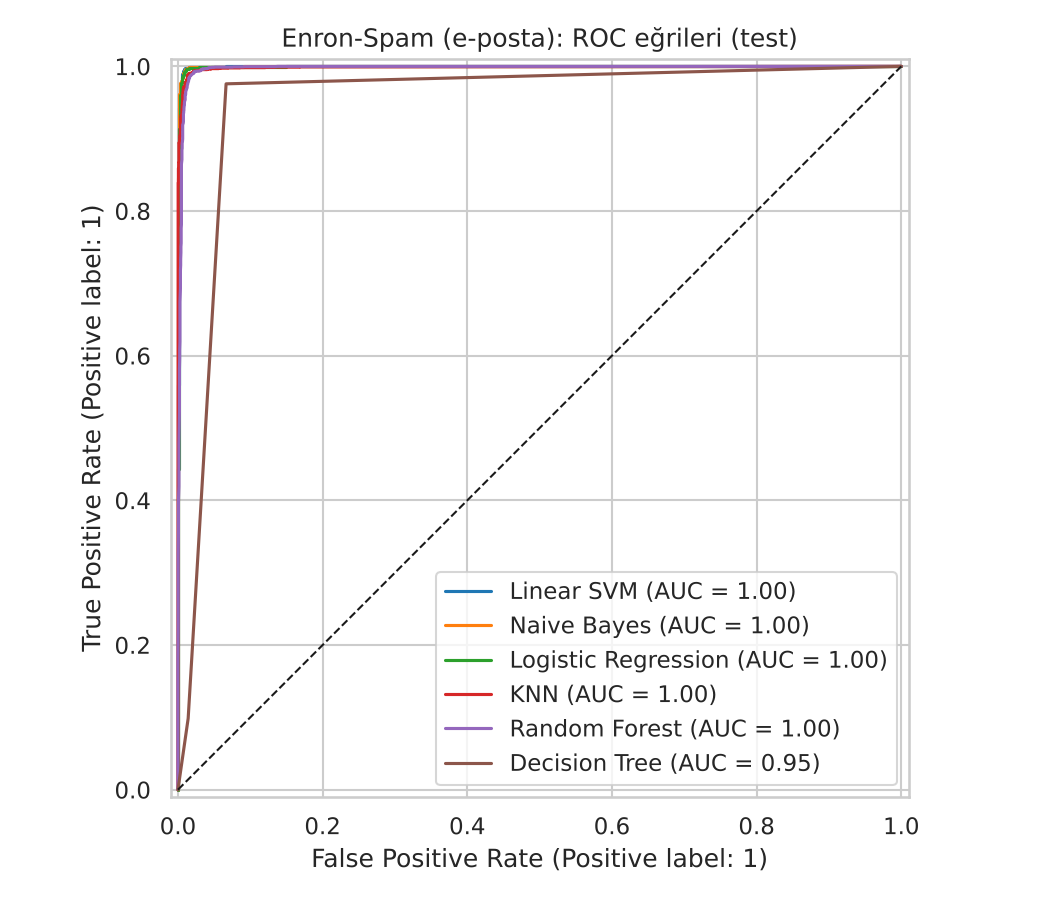

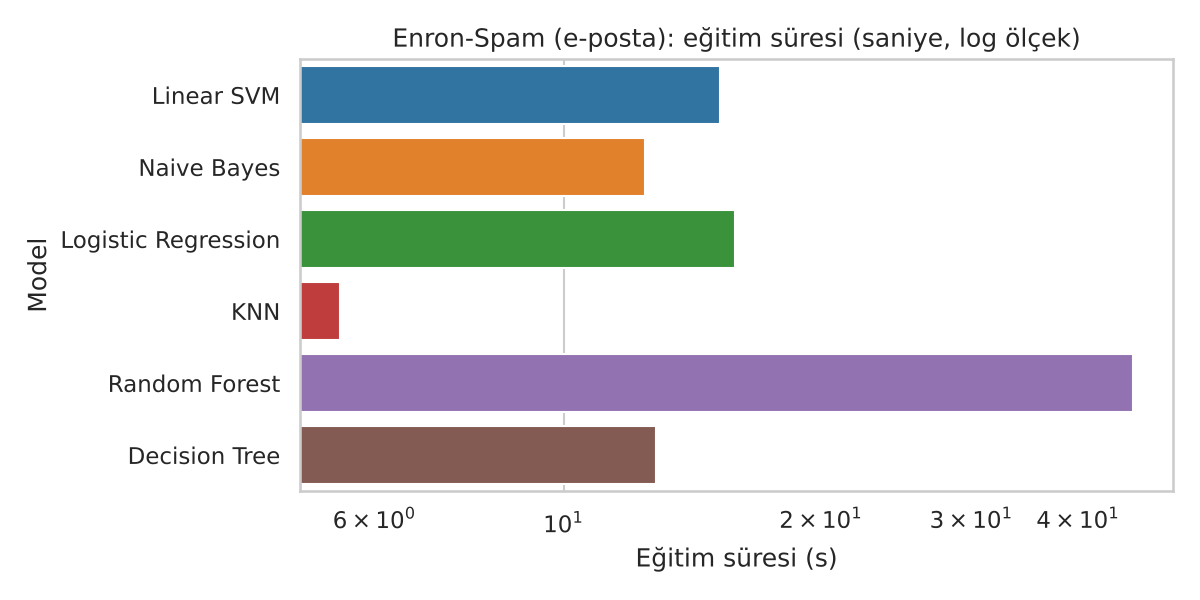

In [8]:
for f in ['metric_comparison.png', 'confusion_matrices.png', 'roc_curves.png', 'training_time.png']:
    display(Image(filename=str(sc.OUT / f)))

## 6. İstatistiksel anlamlılık (McNemar testi)

En iyi model ile diğerleri aynı test örneklerinde karşılaştırılır. p < 0.05 ise fark tesadüfi değildir.

In [9]:
pd.read_csv(sc.OUT / 'mcnemar.csv')

,Karşılaştırma,Yalnız Linear SVM doğru,Yalnız diğeri doğru,p-değeri,Anlamlı (p<0.05)
0,Linear SVM vs Naive Bayes,23,18,0.5330,False
1,Linear SVM vs Logistic Regression,12,6,0.2380,False
2,Linear SVM vs KNN,52,17,0.0000,True
3,Linear SVM vs Random Forest,57,9,0.0000,True
4,Linear SVM vs Decision Tree,232,11,0.0000,True


## 7. Hangi kelimeler spam'i belirliyor?

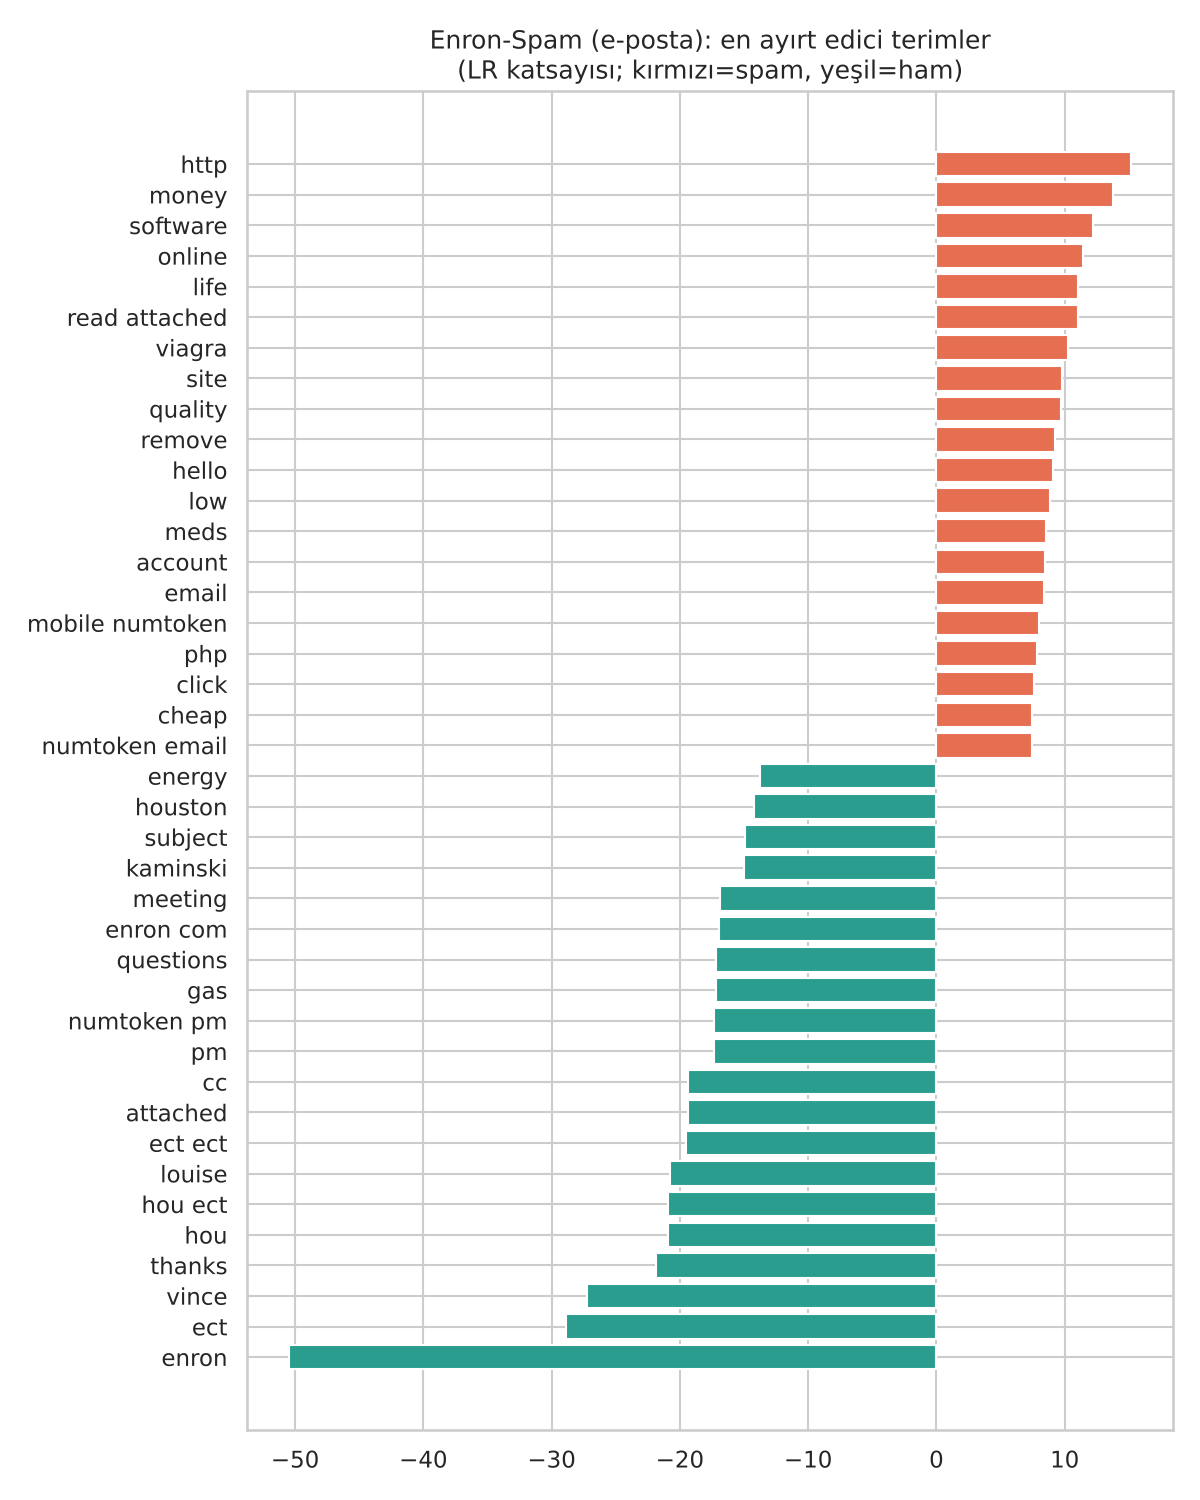

In [10]:
display(Image(filename=str(sc.OUT / 'top_spam_words.png')))

## 8. Hata analizi: en iyi modelin yanlış sınıfladığı örnekler

In [11]:
pd.read_csv(sc.OUT / 'misclassified_samples.csv').head(10)

,gercek,tahmin,skor,metin
0,ham,spam,0.4296,special delivery from marble slab creamery ! y...
1,spam,ham,-0.1047,goldeditor : charting gold for dummies - an in...
2,ham,spam,0.5176,fun pics . htm - - fun pics . htm
3,ham,spam,0.2355,the neural network site www . pfr . com / pton...
4,ham,spam,0.5834,"somewhere to live . . . . . so , would you rec..."
5,spam,ham,-0.2818,meeting on monday unsubscribe ogle irreconcila...
6,ham,spam,0.0397,can you work you legalies into this form .
7,ham,spam,0.1110,restraining order so has the restraining order...
8,ham,spam,0.5327,ripley house photo album
9,ham,spam,1.0881,"fw : quips > remember , amateurs built the ark..."


## 9. Genelleme kontrolü: SMS Spam Collection

Aynı yöntem farklı ve daha dengesiz (%13 spam) bir veri setinde de denenmiştir.

In [12]:
pd.read_csv(sc.OUT / 'dataset_comparison.csv')

,Model,Enron F1,SMS F1
0,Linear SVM,0.9928,0.9292
1,Naive Bayes,0.9919,0.9099
2,Logistic Regression,0.9918,0.9204
3,KNN,0.9867,0.8930
4,Random Forest,0.9846,0.8837
5,Decision Tree,0.9556,0.8407


## 10. Sonuç

In [13]:
best = res.loc[0]
print(f"En iyi algoritma: {best['Model']}  (F1={best['F1']:.4f}, Accuracy={best['Accuracy']:.4f}, ROC-AUC={best['ROC-AUC']:.4f})")
print(open(sc.OUT / 'best_model.txt', encoding='utf-8').read())

En iyi algoritma: Linear SVM  (F1=0.9928, Accuracy=0.9928, ROC-AUC=0.9989)
Enron-Spam (e-posta)
              Model  CV F1 (ort.)  CV F1 (std)  Accuracy  Precision  Recall     F1  ROC-AUC  Eğitim süresi (s)  Tahmin süresi (s)  GridSearch süresi (s)
         Linear SVM        0.9910       0.0015    0.9928     0.9881  0.9976 0.9928   0.9989            15.2322             2.3982                70.7599
        Naive Bayes        0.9912       0.0009    0.9919     0.9914  0.9924 0.9919   0.9996            12.4652             2.0427                74.9868
Logistic Regression        0.9898       0.0014    0.9917     0.9870  0.9966 0.9918   0.9987            15.8864             2.2960                75.4564
                KNN        0.9840       0.0010    0.9867     0.9859  0.9876 0.9867   0.9983             5.4677             9.0766                51.5554
      Random Forest        0.9836       0.0014    0.9845     0.9763  0.9931 0.9846   0.9971            46.4581             1.8507          

## 11. Yeni e-postaları sınıflandırma

In [14]:
from predict import classify
model = fitted[res.loc[0, 'Model']]
ornekler = ['Congratulations! You have won a $1000 gift card. Click here to claim your prize now',
            'Hi team, the meeting is moved to 3pm tomorrow. Please review the attached agenda.',
            'Cheap meds online, no prescription needed, best prices viagra',
            'Can you send me the updated gas nomination spreadsheet for next month?']
pd.DataFrame(classify(model, ornekler), columns=['tahmin', 'skor']).assign(metin=ornekler)

,tahmin,skor,metin
0,spam,0.9676,Congratulations! You have won a $1000 gift car...
1,ham,-1.1652,"Hi team, the meeting is moved to 3pm tomorrow...."
2,spam,1.5638,"Cheap meds online, no prescription needed, bes..."
3,ham,-1.1451,Can you send me the updated gas nomination spr...
